# MobileNetV4 UIB blocks in a ConvNeXt network, trained on CIFAR-10 (BatchNorm vs LayerNorm)

This notebook goes with the report in `README.md`. It:
1. builds the ConvNeXt-UIB model (the UIB block comes from `timm`),
2. trains it with AdamW (set `RUN_TRAINING = True`; on a Colab GPU one 30-epoch run takes a few minutes),
3. plots Loss / Accuracy curves and the BatchNorm vs LayerNorm experiments.

The saved results in `results/` were produced on a 4-core CPU with `run_experiments.sh`.

In [1]:
# On Colab:
# !git clone -b claude/nice-knuth-ot17ij https://github.com/alirezasa/MobileNetV4.git && %cd MobileNetV4
# !pip install -q timm
import json, torch, timm
from src.models import create_model, count_params, UIB_VARIANTS
print('torch', torch.__version__, '| timm', timm.__version__, '| cuda', torch.cuda.is_available())
RUN_TRAINING = False   # True -> retrain every run (writes results/*.json)
DATA = './data'        # CIFAR-10 is downloaded here by torchvision

torch 2.15.0+cu132 | timm 1.0.30 | cuda False


## 1. The model
A ConvNeXt layout (patchify stem → 4 stages separated by `norm + 2×2/2 conv` downsampling → GAP → norm → linear).
Every block is `timm.models._efficientnet_blocks.UniversalInvertedResidual` (UIB) in its **ConvNeXt-like** variant:
`DW 7×7 → PW expand ×4 (+GELU) → PW project → LayerScale → DropPath → + residual`.
The normalisation layer (`norm='bn'|'ln'|'gn1'|'none'`) is passed to every UIB and to the stem/downsampling layers.

In [2]:
print(UIB_VARIANTS)
for norm in ['bn', 'ln']:
    m = create_model('tiny', norm=norm)
    print(f'{norm}: {count_params(m)/1e6:.3f} M params')
m = create_model('tiny', norm='ln')
print(m.stages[1])

{'convnext': (None, 0), 'extra_dw': (None, 3), 'ib': (0, 3), 'ffn': (0, 0)}
bn: 1.907 M params
ln: 1.907 M params
Sequential(
  (0): LayerNorm2d((32,), eps=1e-06, elementwise_affine=True, bias=True)
  (1): Conv2d(32, 64, kernel_size=(2, 2), stride=(2, 2))
  (2): UniversalInvertedResidual(
    (dw_start): ConvNormAct(
      (conv): Conv2d(64, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=64, bias=False)
      (bn): LayerNormAct2d(
        (64,), eps=1e-06, elementwise_affine=True, bias=True
        (drop): Identity()
        (act): Identity()
      )
    )
    (pw_exp): ConvNormAct(
      (conv): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): LayerNormAct2d(
        (256,), eps=1e-06, elementwise_affine=True, bias=True
        (drop): Identity()
        (act): GELU(approximate='none')
      )
    )
    (dw_mid): Identity()
    (se): Identity()
    (pw_proj): ConvNormAct(
      (conv): Conv2d(256, 64, kernel_size=(1, 1), stride=(1, 1), bias=Fal

In [3]:
x = torch.randn(2, 3, 32, 32)
for norm in ['bn', 'ln', 'gn1', 'none']:
    print(norm, create_model('tiny', norm=norm)(x).shape)

bn torch.Size([2, 10])


ln torch.Size([2, 10])


gn1 torch.Size([2, 10])
none torch.Size([2, 10])


## 2. Training
`train.py` uses timm's `create_optimizer_v2('adamw')` (no weight decay on norm/bias parameters), `CosineLRScheduler`
with linear warmup, `LabelSmoothingCrossEntropy`, and `accuracy` / `AverageMeter`.

In [4]:
if RUN_TRAINING:
    !python train.py --data {DATA} --norm bn --epochs 30 --save-ckpt checkpoints/main_bn.pt --out results/main_bn.json
    !python train.py --data {DATA} --norm ln --epochs 30 --save-ckpt checkpoints/main_ln.pt --out results/main_ln.json
    for bs in [4, 16, 128]:
        lr = 2e-3 * (bs / 128) ** 0.5
        for norm in ['bn', 'ln']:
            !python train.py --data {DATA} --norm {norm} --batch-size {bs} --lr {lr} --epochs 10 --warmup-epochs 1 --train-subset 10000 --eval-train-mode --out results/bs_{norm}_{bs}.json
    !python train.py --data {DATA} --norm none --epochs 10 --warmup-epochs 1 --train-subset 10000 --out results/bs_none_128.json

## 3. Loss and accuracy curves (experiment 1)

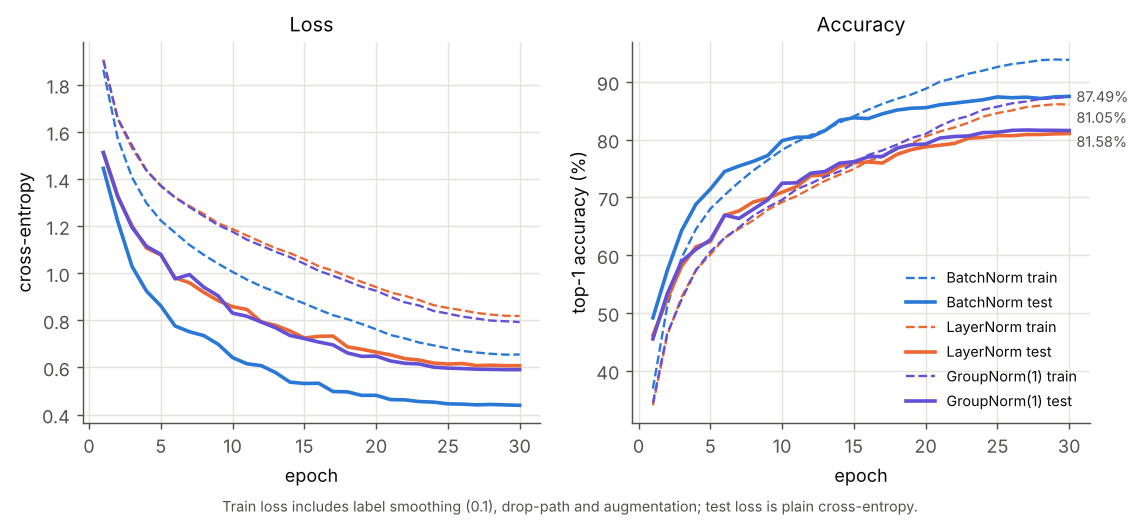

bn epoch | train_loss | train_acc | test_loss | test_acc
       1 | 1.864 |  36.91 | 1.445 |  49.14
       5 | 1.224 |  68.02 | 0.862 |  71.43
      10 | 1.006 |  78.23 | 0.642 |  79.82
      15 | 0.872 |  84.04 | 0.532 |  83.78
      20 | 0.762 |  88.80 | 0.482 |  85.52
      25 | 0.681 |  92.58 | 0.445 |  87.39
      30 | 0.655 |  93.81 | 0.439 |  87.49
ln epoch | train_loss | train_acc | test_loss | test_acc
       1 | 1.907 |  34.01 | 1.512 |  46.14
       5 | 1.373 |  60.09 | 1.078 |  62.37
      10 | 1.188 |  69.20 | 0.858 |  70.90
      15 | 1.060 |  74.90 | 0.725 |  76.01
      20 | 0.941 |  80.57 | 0.665 |  78.75
      25 | 0.852 |  84.59 | 0.614 |  80.71
      30 | 0.819 |  86.09 | 0.607 |  81.05


In [5]:
!python plot_results.py > /dev/null
from IPython.display import Image, Markdown, display
display(Image('results/figures/main_curves.png'))
for n in ['bn', 'ln']:
    h = json.load(open(f'results/main_{n}.json'))
    print(n, 'epoch | train_loss | train_acc | test_loss | test_acc')
    for e in h['epochs']:
        if e['epoch'] % 5 == 0 or e['epoch'] == 1:
            print(f"   {e['epoch']:5d} | {e['train_loss']:.3f} | {e['train_acc']:6.2f} | {e['test_loss']:.3f} | {e['test_acc']:6.2f}")

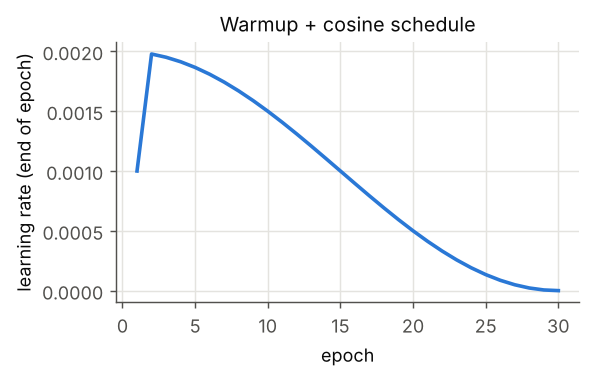

In [6]:
display(Image('results/figures/lr_schedule.png'))

## 4. BatchNorm vs LayerNorm (experiment 2: batch size)

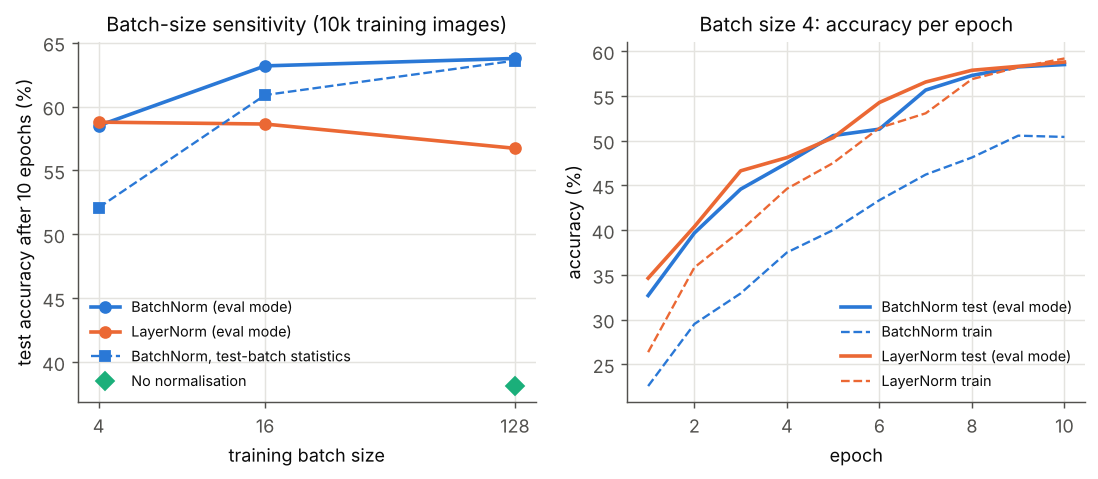

## Experiment 1: full CIFAR-10, batch 128, 30 epochs

| norm | params | final test acc | best test acc | final train acc | final test loss | sec / epoch |
|---|---|---|---|---|---|---|
| BatchNorm | 1.91M | 87.49 | 87.49 | 93.81 | 0.439 | 107 |
| LayerNorm | 1.91M | 81.05 | 81.05 | 86.09 | 0.607 | 102 |
| GroupNorm(1) | 1.91M | 81.58 | 81.67 | 87.46 | 0.591 | 101 |

## Experiment 2: batch-size sensitivity (10k images, 10 epochs, lr = 2e-3·sqrt(B/128))

| norm | batch | test acc (eval mode) | test acc (BN batch stats) | train acc | test loss | sec / epoch |
|---|---|---|---|---|---|---|
| BatchNorm | 4 | 58.50 | 52.09 | 50.41 | 1.215 | 102 |
| LayerNorm | 4 | 58.78 | — | 59.18 | 1.183 | 103 |
| BatchNorm | 16 | 63.18 | 60.90 | 61.67 | 1.070 | 41 |
| LayerNorm | 16 | 58.63 | — | 58.46 | 1.194 | 40 |
| BatchNorm | 128 | 63.76 | 63.59 | 64.85 | 1.050 | 24 |
| LayerNorm | 128 | 56.73 | — | 56.23 | 1.237 | 21 |
| No norm | 128 | 38.13 | — | 35.12 | 1.799 | 15 |


In [7]:
display(Image('results/figures/batch_size.png'))
display(Markdown(open('results/summary.md').read()))

## 5. BatchNorm vs LayerNorm: analysis without training (`bn_vs_ln_analysis.py`)

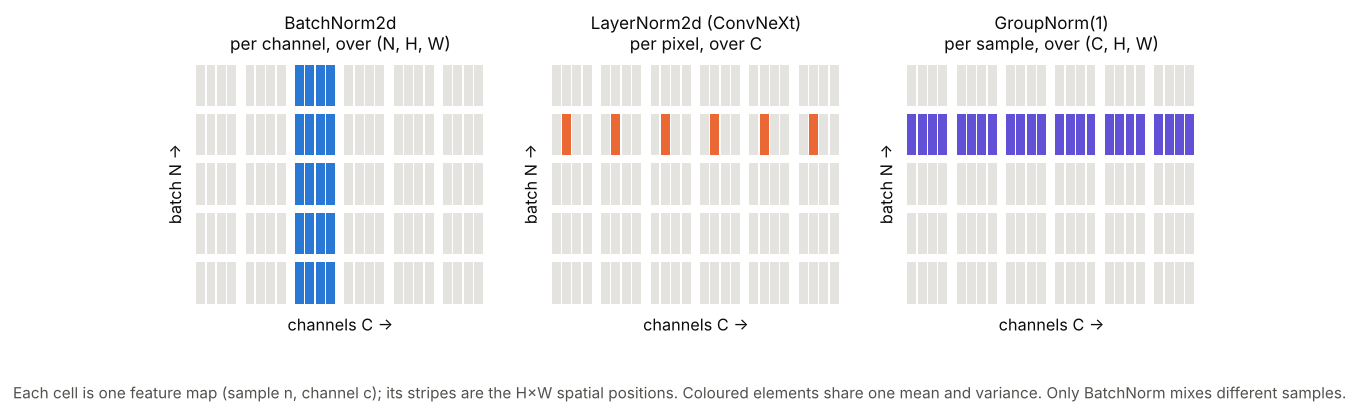

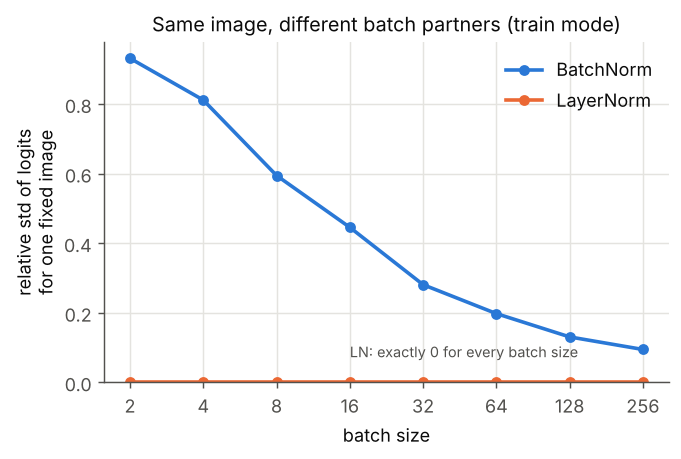

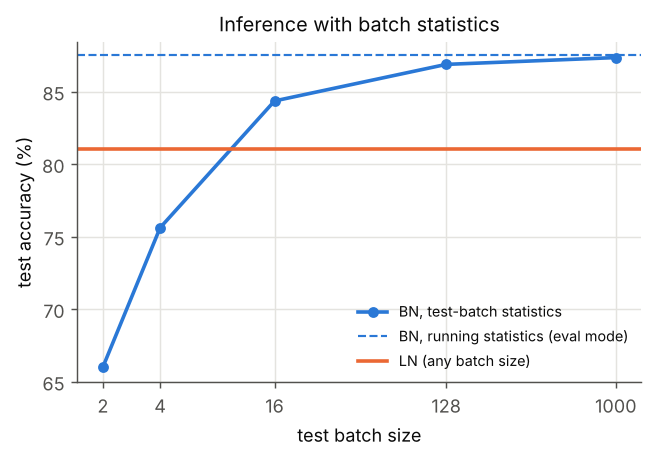

{
 "axes_check": {
  "BatchNorm2d == normalise over (N,H,W) per channel": 2.384185791015625e-07,
  "LayerNorm2d (ConvNeXt) == normalise over C per (n,h,w)": 4.76837158203125e-07,
  "GroupNorm(1) == normalise over (C,H,W) per sample": 4.76837158203125e-07,
  "number of statistics (mean,var pairs) BN / LN / GN1": [
   16,
   288,
   8
  ]
 },
 "models": {
  "bn": "checkpoints/main_bn.pt",
  "ln": "checkpoints/main_ln.pt"
 },
 "batch_dependence_rel_std": {
  "bn": {
   "2": 0.9317655563354492,
   "4": 0.8118056654930115,
   "8": 0.5948845744132996,
   "16": 0.4457876980304718,
   "32": 0.2810341417789459,
   "64": 0.19786706566810608,
   "128": 0.13086764514446259,
   "256": 0.09476345032453537
  },
  "bn_pred_changes": {
   "2": 4,
   "4": 2,
   "8": 3,
   "16": 2,
   "32": 1,
   "64": 0,
   "128": 0,
   "256": 0
  },
  "ln": {
   "2": 0.0,
   "4": 0.0,
   "8": 0.0,
   "16": 0.0,
   "32": 0.0,
   "64": 0.0,
   "128": 0.0,
   "256": 0.0
  },
  "ln_pred_changes": {
   "2": 0,
   "4": 0,
  

In [8]:
if RUN_TRAINING:
    !python bn_vs_ln_analysis.py --data {DATA}
for f in ['norm_axes', 'batch_dependence', 'bn_test_batch_stats']:
    display(Image(f'results/figures/{f}.png'))
print(json.dumps(json.load(open('results/bn_vs_ln_analysis.json')), indent=1))